# Predição de mortalidade neonatal no RJ com dados abertos (SINASC × SIM, 2017–2023)

**Disciplina:** Introdução ao Aprendizado de Máquina para a Saúde (UFF, 2026.2).

**Artigo de referência:** Batista AFM, Diniz CSG, Bonilha EA, Kawachi I, Chiavegatto Filho ADP.
*Neonatal mortality prediction with routinely collected data: a machine learning approach.*
BMC Pediatrics 21:322 (2021).

**Perguntas:**
1. O desempenho do artigo (XGBoost, AUROC 0,971) se reproduz no estado do RJ só com
   microdados públicos, que não trazem identificadores?
2. Quanto se perde com um modelo que usa apenas informações disponíveis na admissão para o parto?
3. O modelo é calibrado e funciona igualmente por raça/cor e escolaridade da mãe e entre capital e interior?

Este notebook é a Parte 2 (Demonstração) do projeto e executa o fluxo inteiro:
download → linkage → pré-processamento → ajuste → avaliação → figuras.

## 1. Dependências do ambiente de execução
As versões exatas estão em `requirements.txt`. Para reproduzir:
```bash
uv venv .venv && uv pip install --python .venv/bin/python -r requirements.txt
.venv/bin/python -m src.experimento        # ≈ 1 h com 32 núcleos; grava data/resultados.pkl
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebook/mortalidade_neonatal_rj.ipynb
```
O experimento pesado (busca de hiperparâmetros, bootstrap e SHAP) roda em `src/experimento.py`.
O notebook reaproveita o resultado gravado e só executa o experimento se esse arquivo não existir.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import lightgbm, optuna, shap, sklearn, xgboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

from src import download, evaluate, experimento, linkage, models, preprocess

FIG = RAIZ / "figuras"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

# Paleta categórica validada (slots 1–3 passam em todos os pares, inclusive daltonismo).
COR = {"LR": "#2a78d6", "XGBoost": "#eb6834", "LightGBM": "#1baf7a"}
TINTA, TINTA2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})
NOME_CONJ = {"A_completo": "A · completo", "B_pre_parto": "B · pré-parto"}
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| lightgbm", lightgbm.__version__, "| optuna", optuna.__version__, "| shap", shap.__version__)

/home/clebinho/uff/mestrado/terceira_opcao/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | optuna 5.0.0 | shap 0.52.0


## 2. Carregamento do dataset
São 7 arquivos do SINASC (`DNRJ2017–2023.dbc`) e 8 do SIM (`DORJ2017–2024.dbc`), baixados do FTP público do
DATASUS: <ftp://ftp.datasus.gov.br/dissemin/publicos/>. O SIM vai até 2024 para incluir os óbitos
de quem nasceu no fim de 2023. O download é idempotente: arquivos já baixados são reaproveitados.

In [2]:
arquivos = download.baixar_tudo(RAIZ / "data" / "raw")
nv_bruto = download.carregar("DN", download.ANOS_NASCIMENTO, RAIZ / "data" / "raw")
do_bruto = download.carregar("DO", download.ANOS_OBITO, RAIZ / "data" / "raw")
print(f"SINASC: {len(nv_bruto):,} nascidos vivos, {nv_bruto.shape[1]} colunas")
print(f"SIM:    {len(do_bruto):,} óbitos, {do_bruto.shape[1]} colunas")
print("NUMERODN nos arquivos públicos?", "NUMERODN" in nv_bruto, "NUMERODN" in do_bruto)

SINASC: 1,397,216 nascidos vivos, 63 colunas
SIM:    1,227,542 óbitos, 89 colunas
NUMERODN nos arquivos públicos? False False


## 3. Pré-processamento
### 3.1 Linkage SINASC × SIM sem identificadores
Os arquivos públicos não trazem o número da DN. A Declaração de Óbito de menores de 1 ano repete dados
do nascimento, e o pareamento usa essa redundância:
- chaves compostas em cascata, da mais restritiva à mais tolerante a campos ausentes;
- em cada passada, só pares 1:1 são aceitos.

Para estimar os falsos pares, usamos campos que nunca entram nas chaves (escolaridade da mãe e perdas
fetais anteriores). A concordância na passada 1 serve de referência para pares verdadeiros, e a
concordância entre pares aleatórios com a mesma data e o mesmo sexo serve de referência para o acaso.

In [3]:
for i, chave in enumerate(linkage.PASSADAS, 1):
    print(i, " + ".join(chave))

1 DTNASC + SEXO + CODMUNRES + PESO + IDADEMAE + SEMAGESTAC + GRAVIDEZ + PARTO
2 DTNASC + SEXO + CODMUNRES + PESO + IDADEMAE
3 DTNASC + SEXO + CODMUNRES + PESO + CODESTAB
4 DTNASC + SEXO + PESO + IDADEMAE
5 DTNASC + SEXO + CODMUNRES + IDADEMAE + SEMAGESTAC
6 DTNASC + SEXO + CODMUNRES + CODESTAB + IDADEMAE


In [4]:
R = experimento.carregar() if experimento.RESULTADOS.exists() else experimento.rodar()
rel = R["linkage"]
print(f"Óbitos neonatais no SIM: {rel['n_obitos']:,} · pareados: {rel['n_pareados']:,} "
      f"({100 * rel['n_pareados'] / rel['n_obitos']:.1f}%)")
rel["por_ano"]

Óbitos neonatais no SIM: 12,039 · pareados: 10,849 (90.1%)


,nascidos_vivos,obitos_neonatais_sim,obitos_pareados,pct_pareado,tmn_sim_por_mil,tmn_pareada_por_mil
DTNASC,,,,,,
2017,223224,1914,1720,89.9,8.57,7.71
2018,220499,1837,1638,89.2,8.33,7.43
2019,207989,1817,1652,90.9,8.74,7.94
2020,199124,1744,1543,88.5,8.76,7.75
2021,189866,1627,1464,90.0,8.57,7.71
2022,180369,1523,1388,91.1,8.44,7.70
2023,176145,1577,1444,91.6,8.95,8.20


In [5]:
rel["falsos_pares"]

,n_pares,conc_ESCMAE,falsos_ESCMAE,acaso_ESCMAE,conc_QTDFILMORT,falsos_QTDFILMORT,acaso_QTDFILMORT
1,5338,79.0,0.0,40.3,90.0,0.0,60.7
2,3521,76.7,6.0,40.3,87.5,8.0,60.7
3,771,66.5,32.0,40.3,85.1,17.0,60.7
4,439,74.7,11.0,40.3,86.7,11.0,60.7
5,492,72.9,16.0,40.3,86.1,13.0,60.7
6,288,70.5,22.0,40.3,83.7,22.0,60.7


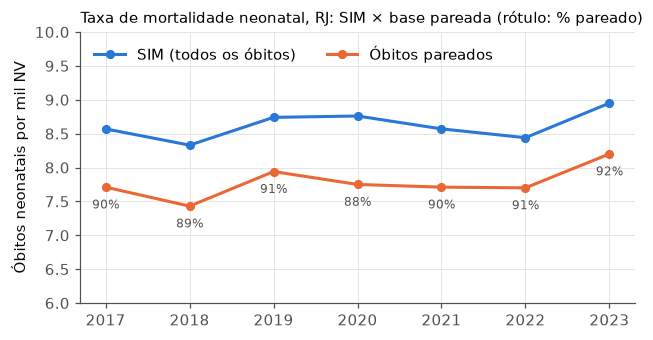

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
pa = rel["por_ano"]
ax.plot(pa.index, pa["tmn_sim_por_mil"], marker="o", ms=5, color=COR["LR"], label="SIM (todos os óbitos)")
ax.plot(pa.index, pa["tmn_pareada_por_mil"], marker="o", ms=5, color=COR["XGBoost"], label="Óbitos pareados")
for x, y, t in zip(pa.index, pa["tmn_pareada_por_mil"], pa["pct_pareado"]):
    ax.annotate(f"{t:.0f}%", (x, y), textcoords="offset points", xytext=(0, -14), ha="center",
                fontsize=8, color=TINTA2)
ax.set_ylim(6, 10); ax.set_ylabel("Óbitos neonatais por mil NV")
ax.set_title("Taxa de mortalidade neonatal, RJ: SIM × base pareada (rótulo: % pareado)", loc="left", fontsize=10)
ax.legend(loc="upper left", ncol=2)
fig.savefig(FIG / "linkage_por_ano.png")

### 3.2 Limpeza, exclusões e variáveis
- **Numéricas:** códigos de "ignorado" (99, ou 9999 no peso) viram ausentes. Mantemos idade da mãe e
  do pai, histórico obstétrico, semanas de gestação, consultas e mês de início do pré-natal, Apgar e peso.
- **Categóricas:** o "9" (ignorado) e o campo vazio viram categorias próprias, porque o não
  preenchimento da DN também informa sobre a qualidade da assistência.
- **Exclusão do artigo:** idade gestacional fora de 15–45 semanas. Nenhum registro do RJ caiu nela,
  porque o SINASC já valida esse campo.
- **Imputação e encoding:** para o XGBoost e o LightGBM, os ausentes e as categorias são tratados
  nativamente pelas árvores. Na regressão logística, imputação pela mediana com indicador de ausência,
  padronização e one-hot são ajustados só no treino.

In [7]:
R["fluxo"]

,Etapa,n
0,"Nascidos vivos residentes no RJ, 2017–2023",1397216
1,Com data de nascimento válida,1397216
2,Idade gestacional entre 15 e 45 semanas (ou au...,1397216


In [8]:
base = pd.read_parquet(RAIZ / "data" / "base_analitica.parquet")
print("Conjunto A (completo):", len(preprocess.VARS_COMPLETO), "variáveis")
print("Conjunto B (pré-parto):", len(preprocess.VARS_PRE_PARTO), "variáveis:",
      ", ".join(preprocess.ROTULOS[v] for v in preprocess.VARS_PRE_PARTO))
aus = (base[[*preprocess.NUMERICAS]].isna().mean() * 100).round(1).rename(preprocess.ROTULOS)
print("\n% ausente nas numéricas:\n", aus.sort_values(ascending=False).to_string())

Conjunto A (completo): 28 variáveis
Conjunto B (pré-parto): 17 variáveis: Idade da mãe, Idade do pai, Filhos vivos, Perdas fetais/abortos, Gestações anteriores, Partos vaginais anteriores, Cesáreas anteriores, Semanas de gestação, Consultas de pré-natal, Mês de início do pré-natal, Estado civil da mãe, Escolaridade da mãe, Tipo de gravidez, Raça/cor da mãe, Apresentação, Adequação do pré-natal (Kotelchuck), Residente na capital

% ausente nas numéricas:
 Idade do pai                  54.2
Mês de início do pré-natal     6.7
Consultas de pré-natal         2.4
Perdas fetais/abortos          2.1
Cesáreas anteriores            1.8
Partos vaginais anteriores     1.7
Apgar 1º min                   1.4
Filhos vivos                   1.3
Semanas de gestação            1.2
Apgar 5º min                   1.1
Gestações anteriores           0.9
Idade da mãe                   0.0
Peso ao nascer                 0.0


### 3.3 Estatística descritiva
Taxa de mortalidade neonatal (TMN, por mil nascidos vivos) nas principais variáveis da DN.

In [9]:
def tmn(df, col, rotulos=None):
    g = df.groupby(col, observed=True)["obito_neonatal"].agg(["size", "sum", "mean"])
    g.columns = ["NV", "óbitos", "TMN (‰)"]
    g["TMN (‰)"] *= 1000
    return g.rename(index=rotulos) if rotulos else g

faixa_peso = pd.cut(base["PESO"], [0, 1500, 2500, 4000, 8000], right=False,
                    labels=["< 1.500 g", "1.500–2.499 g", "2.500–3.999 g", "≥ 4.000 g"])
faixa_ig = pd.cut(base["SEMAGESTAC"], [0, 32, 37, 42, 46], right=False,
                  labels=["< 32 sem", "32–36 sem", "37–41 sem", "≥ 42 sem"])
desc = pd.concat({
    "Peso ao nascer": tmn(base.assign(f=faixa_peso), "f"),
    "Idade gestacional": tmn(base.assign(f=faixa_ig), "f"),
    "Apgar 5º min < 7": tmn(base.assign(f=np.where(base["APGAR5"] < 7, "sim", "não")), "f"),
    "Anomalia congênita": tmn(base, "IDANOMAL", {"1": "sim", "2": "não", "9": "ignorado", "ausente": "ausente"}),
    "Raça/cor da mãe": tmn(base, "raca_mae"),
    "Escolaridade da mãe": tmn(base, "escol_mae"),
})
desc.to_csv(FIG / "descritiva_tmn.csv")
desc

NV  óbitos  TMN (‰)
Peso ao nascer      < 1.500 g                    22725    6468  284.620
                    1.500–2.499 g               110053    1904   17.301
                    2.500–3.999 g              1194900    2336    1.955
                    ≥ 4.000 g                    69513     141    2.028
Idade gestacional   < 32 sem                     23211    6068  261.428
                    32–36 sem                   133100    2069   15.545
                    37–41 sem                  1202793    2449    2.036
                    ≥ 42 sem                     21543      41    1.903
Apgar 5º min < 7    não                        1381935    6233    4.510
                    sim                          15281    4616  302.074
Anomalia congênita  sim                           9614    1294  134.595
                    não                        1347578    9231    6.850
                    ignorado                     31509     263    8.347
                    ausente                       8515      61    7.164
Raça/cor da mãe     Amarela                       5037      53   10.522
                    Branca                      460545    2928    6.358
                    Ignorada                     25196     213    8.454
                    Indígena                      1136       9    7.923
                    Parda                       713871    5843    8.185
                    Preta                       191431    1803    9.419
Escolaridade da mãe Fund. incompleto ou menos   331600    3099    9.346
                    Ignorada                     23952     215    8.976
                    Médio                       741665    5810    7.834
                    Superior                    299999    1725    5.750

### 3.4 Amostras de treino, validação e teste (validação temporal)
| Uso | Anos | Papel |
|---|---|---|
| Ajuste | 2017–2021 | treino dos modelos |
| Validação | 2022 | busca de hiperparâmetros (Optuna), *early stopping*, recalibração isotônica e escolha do limiar |
| Teste | 2023 | avaliação final, usada uma única vez |

O esquema espelha o do artigo, que treinou em 2012–2016 e testou em 2017. A pergunta avaliada é se um
modelo treinado no passado funciona no ano seguinte.

In [10]:
pd.DataFrame(R["amostras"]).T

,n,óbitos,TMN (‰)
ajuste 2017–2021,1.041e+06,8017.0,7.703
validação 2022,1.804e+05,1388.0,7.695
teste 2023,1.761e+05,1444.0,8.198


## 4. Modelos
**Regressão logística:** $P(y=1\mid\mathbf{x}) = \sigma(\beta_0 + \boldsymbol\beta^\top\mathbf{x})$, com
$\sigma(z) = 1/(1+e^{-z})$. Ajuste por máxima verossimilhança com penalização L2 ($C$ escolhido na validação) e
`class_weight="balanced"`.

**XGBoost / LightGBM:** $F(\mathbf{x}) = \sum_{k=1}^{K} f_k(\mathbf{x})$, em que cada $f_k$ é uma árvore de regressão, e
$P(y=1\mid\mathbf{x}) = \sigma(F(\mathbf{x}))$. As árvores entram em sequência, e a árvore $k$ minimiza a expansão
de 2ª ordem da log-loss mais $\Omega(f) = \gamma T + \tfrac12\lambda\lVert w\rVert^2 + \alpha\lVert w\rVert_1$.

**Peso de classe (`scale_pos_weight`):** é tratado como hiperparâmetro, com três opções: nenhum,
$\sqrt{n_0/n_1}$ ou $n_0/n_1$. Como qualquer peso distorce as probabilidades, uma **regressão isotônica**
ajustada em 2022 recalibra as saídas. Ela é monótona, então não altera a ordenação.

**Complexidade:** o XGBoost com histogramas custa $O(K \cdot n \cdot d)$ por ajuste ($K$ árvores, $n$ registros,
$d$ variáveis), e a predição custa $O(K \cdot \text{profundidade})$ por registro. A regressão logística custa
$O(n \cdot d')$ por iteração do L-BFGS, com $d'$ colunas após o one-hot.

### 4.1 Hiperparâmetros
A busca bayesiana (TPE, Optuna) teve 30 tentativas para o XGBoost e 20 para o LightGBM. O objetivo
foi a AUPRC na validação de 2022, com *early stopping* de 100 árvores.

In [11]:
params = pd.DataFrame({f"{NOME_CONJ[c]} · {m}": pd.Series(v) for (c, m), v in R["params"].items()})
params.to_csv(FIG / "hiperparametros.csv")
params

,A · completo · LR,A · completo · XGBoost,A · completo · LightGBM,B · pré-parto · LR,B · pré-parto · XGBoost,B · pré-parto · LightGBM
C,1.0,NaN,NaN,0.01,NaN,NaN
colsample_bytree,NaN,0.520,0.881,NaN,0.627,0.881
gamma,NaN,0.001,NaN,NaN,0.162,NaN
learning_rate,NaN,0.059,0.068,NaN,0.041,0.068
max_depth,NaN,5.000,NaN,NaN,4.000,NaN
min_child_samples,NaN,NaN,113.000,NaN,NaN,113.000
min_child_weight,NaN,5.955,NaN,NaN,18.076,NaN
n_arvores,NaN,207.000,124.000,NaN,409.000,143.000
num_leaves,NaN,NaN,17.000,NaN,NaN,17.000
reg_alpha,NaN,0.234,NaN,NaN,2.248,NaN


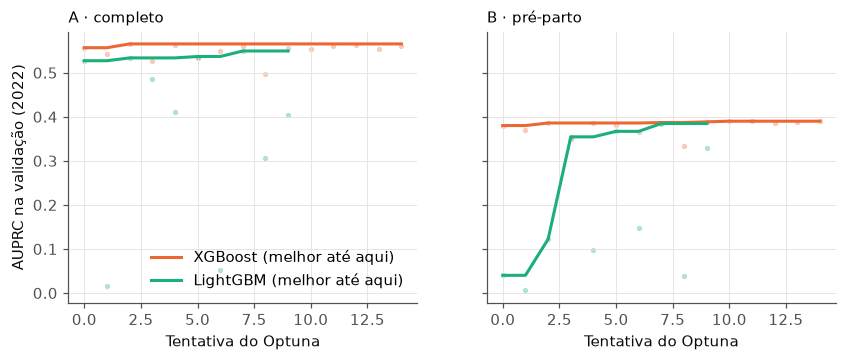

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, conj in zip(axes, preprocess.CONJUNTOS):
    for nome, cor in [("XGBoost", COR["XGBoost"]), ("LightGBM", COR["LightGBM"])]:
        t = R["estudos"][(conj, nome)]
        ax.plot(t["number"], t["value"].cummax(), color=cor, label=f"{nome} (melhor até aqui)")
        ax.scatter(t["number"], t["value"], s=12, color=cor, alpha=0.35, linewidths=0)
    ax.set_title(NOME_CONJ[conj], loc="left", fontsize=10); ax.set_xlabel("Tentativa do Optuna")
axes[0].set_ylabel("AUPRC na validação (2022)"); axes[0].legend(loc="lower right")
fig.savefig(FIG / "optuna.png")

## 5. Execução
### 5.1 Curvas por iteração (XGBoost final)
Log-loss e AUPRC a cada árvore, no ajuste (2017–2021) e na validação (2022). A linha vertical marca a
árvore escolhida pelo *early stopping*. Log-loss e AUPRC ficam em painéis separados porque têm escalas diferentes.

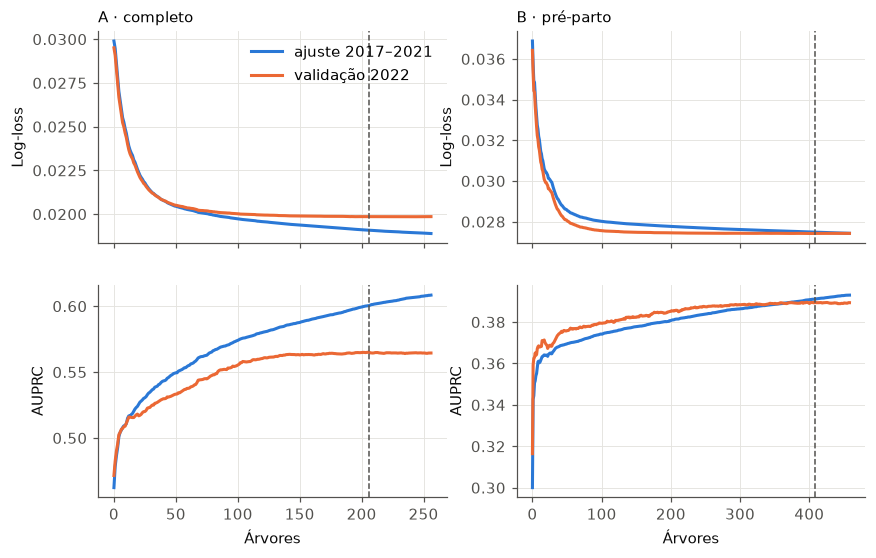

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5), sharex="col")
for j, conj in enumerate(preprocess.CONJUNTOS):
    c = R["curvas"][conj]
    melhor = R["params"][(conj, "XGBoost")]["n_arvores"] - 1
    for i, (met, rot) in enumerate([("logloss", "Log-loss"), ("aucpr", "AUPRC")]):
        ax = axes[i, j]
        ax.plot(c.index, c[f"treino_{met}"], color=COR["LR"], label="ajuste 2017–2021")
        ax.plot(c.index, c[f"valid_{met}"], color=COR["XGBoost"], label="validação 2022")
        ax.axvline(melhor, color=TINTA2, lw=1, ls="--")
        ax.set_ylabel(rot)
        if i == 0:
            ax.set_title(NOME_CONJ[conj], loc="left", fontsize=10)
        else:
            ax.set_xlabel("Árvores")
axes[0, 0].legend()
fig.savefig(FIG / "curvas_iteracao.png")

### 5.2 Desempenho no teste (2023)
O limiar de classificação foi escolhido em 2022 para maximizar o F1 e só depois aplicado a 2023. Os IC 95%
vêm de 500 reamostras bootstrap estratificadas.

A regressão isotônica é monótona, mas é uma função em degraus e cria empates. Por isso as métricas de
**ordenação** (AUROC, AUPRC e óbitos no top 5%) usam o escore bruto do modelo. As métricas que dependem do
**valor** da probabilidade (Brier, O/E e as métricas no limiar) usam a probabilidade recalibrada.

In [14]:
def tabela_metricas(R):
    linhas = []
    for (conj, nome), t in R["metricas"].items():
        linha = {"Conjunto": NOME_CONJ[conj], "Modelo": nome}
        for m, r in t.iterrows():
            linha[m] = f"{r.valor:.3f} ({r.ic_inf:.3f}–{r.ic_sup:.3f})"
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index(["Conjunto", "Modelo"])

tab = tabela_metricas(R)
tab.to_csv(FIG / "metricas_teste.csv")
tab.T

Conjunto                 A · completo                                                  B · pré-parto                                          
Modelo                             LR              XGBoost             LightGBM                   LR              XGBoost             LightGBM
AUROC             0.953 (0.946–0.961)  0.956 (0.948–0.962)  0.956 (0.949–0.963)  0.887 (0.875–0.898)  0.890 (0.879–0.901)  0.891 (0.880–0.902)
AUPRC             0.533 (0.509–0.563)  0.576 (0.553–0.605)  0.573 (0.551–0.600)  0.382 (0.357–0.413)  0.406 (0.380–0.437)  0.399 (0.372–0.429)
Brier             0.005 (0.005–0.005)  0.005 (0.005–0.005)  0.005 (0.005–0.005)  0.006 (0.006–0.006)  0.006 (0.006–0.006)  0.006 (0.006–0.006)
F1                0.546 (0.526–0.567)  0.595 (0.574–0.617)  0.580 (0.560–0.600)  0.476 (0.455–0.496)  0.478 (0.457–0.500)  0.469 (0.449–0.490)
Precisão          0.524 (0.503–0.545)  0.633 (0.612–0.657)  0.565 (0.544–0.587)  0.475 (0.454–0.498)  0.487 (0.465–0.510)  0.464 (0.444–0.488)
Sensibilidade     0.570 (0.544–0.594)  0.562 (0.537–0.588)  0.596 (0.573–0.623)  0.477 (0.451–0.501)  0.470 (0.446–0.495)  0.474 (0.449–0.498)
Especificidade    0.996 (0.995–0.996)  0.997 (0.997–0.998)  0.996 (0.996–0.997)  0.996 (0.995–0.996)  0.996 (0.996–0.996)  0.995 (0.995–0.996)
VPN               0.996 (0.996–0.997)  0.996 (0.996–0.997)  0.997 (0.996–0.997)  0.996 (0.995–0.996)  0.996 (0.995–0.996)  0.996 (0.995–0.996)
Óbitos no top 5%  0.862 (0.843–0.880)  0.868 (0.851–0.885)  0.866 (0.850–0.883)  0.706 (0.684–0.730)  0.716 (0.695–0.737)  0.708 (0.689–0.730)
O/E               1.014 (0.992–1.040)  1.015 (0.989–1.042)  1.019 (0.994–1.047)  1.048 (1.023–1.072)  1.046 (1.023–1.071)  1.049 (1.025–1.074)

**Comparação com o artigo (XGBoost, conjunto completo):**

In [15]:
artigo = {"AUROC": 0.971, "AUPRC": 0.586, "F1": 0.548, "Precisão": 0.729, "Sensibilidade": 0.440,
          "Especificidade": 0.99, "VPN": 0.997, "Óbitos no top 5%": 0.90}
nosso = R["metricas"][("A_completo", "XGBoost")]
comp = pd.DataFrame({"Batista et al. (SP, 2017)": artigo, "Este trabalho (RJ, 2023)": nosso["valor"]}).loc[list(artigo)]
comp.to_csv(FIG / "comparacao_artigo.csv")
comp.round(3)

,"Batista et al. (SP, 2017)","Este trabalho (RJ, 2023)"
AUROC,0.971,0.956
AUPRC,0.586,0.576
F1,0.548,0.595
Precisão,0.729,0.633
Sensibilidade,0.440,0.562
Especificidade,0.990,0.997
VPN,0.997,0.996
Óbitos no top 5%,0.900,0.868


In [16]:
pd.DataFrame(R["deltas"]).T

,delta,ic_inf,ic_sup,p_bilateral
XGBoost A − B (AUROC),0.066,5.632e-02,0.076,0.000
"XGBoost − LR, A_completo (AUROC)",0.003,7.617e-05,0.005,0.052
"XGBoost − LR, B_pre_parto (AUROC)",0.003,-1.686e-03,0.008,0.200
XGBoost A − B (AUPRC),0.169,1.451e-01,0.192,0.000
"XGBoost − LR, A_completo (AUPRC)",0.042,2.688e-02,0.059,0.000
"XGBoost − LR, B_pre_parto (AUPRC)",0.024,9.505e-03,0.038,0.000


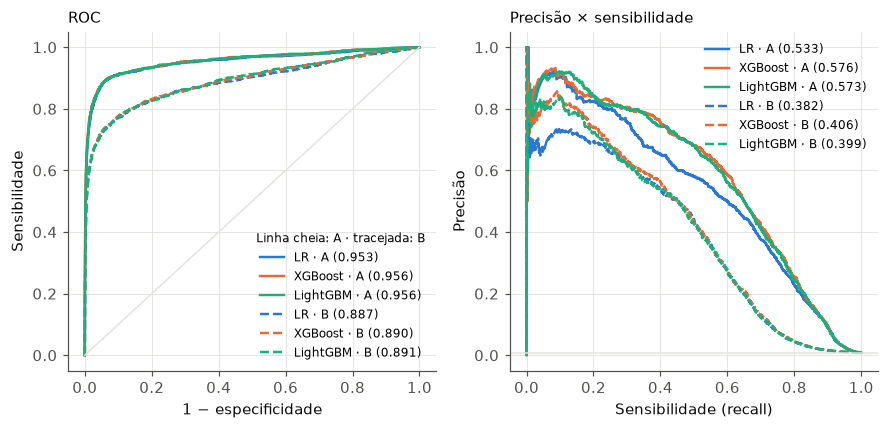

In [17]:
y_te = R["y_teste"]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for (conj, nome), pr in R["predicoes"].items():
    p = pr["bruto"]  # curvas de ordenação: escore bruto (a isotônica cria empates)
    ls = "-" if conj == "A_completo" else "--"
    fpr, tpr, _ = roc_curve(y_te, p)
    prec, rec, _ = precision_recall_curve(y_te, p)
    auc = R["metricas"][(conj, nome)].loc["AUROC", "valor"]
    ap = R["metricas"][(conj, nome)].loc["AUPRC", "valor"]
    axes[0].plot(fpr, tpr, ls=ls, color=COR[nome], lw=1.6, label=f"{nome} · {NOME_CONJ[conj][0]} ({auc:.3f})")
    axes[1].plot(rec, prec, ls=ls, color=COR[nome], lw=1.6, label=f"{nome} · {NOME_CONJ[conj][0]} ({ap:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRADE, lw=1)
axes[0].set(xlabel="1 − especificidade", ylabel="Sensibilidade", title="ROC")
axes[1].axhline(y_te.mean(), color=GRADE, lw=1)
axes[1].set(xlabel="Sensibilidade (recall)", ylabel="Precisão", title="Precisão × sensibilidade")
axes[0].legend(title="Linha cheia: A · tracejada: B", fontsize=8, title_fontsize=8, loc="lower right")
axes[1].legend(fontsize=8, loc="upper right")
for ax in axes:
    ax.title.set_fontsize(10); ax.title.set_ha("left"); ax.title.set_x(0)
fig.savefig(FIG / "roc_pr.png")

**Captura de óbitos por fração da população priorizada.** Ao ordenar os recém-nascidos pelo risco
previsto, a curva mostra que fração dos óbitos está entre os x% de maior risco. O artigo reporta mais de
90% dos óbitos nos 5% de maior risco.

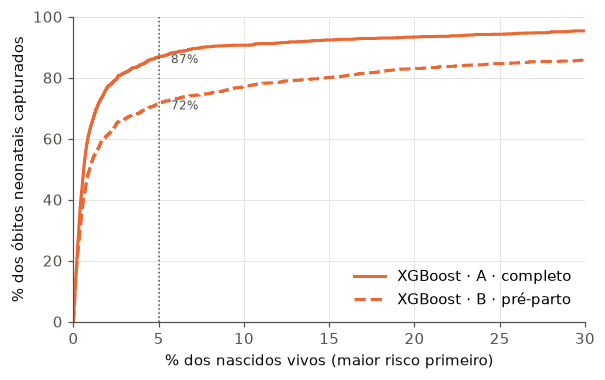

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for conj, ls in [("A_completo", "-"), ("B_pre_parto", "--")]:
    p = R["predicoes"][(conj, "XGBoost")]["bruto"]
    ordem = np.argsort(-p, kind="stable")
    capt = np.cumsum(y_te[ordem]) / y_te.sum()
    frac = np.arange(1, len(p) + 1) / len(p)
    ax.plot(frac * 100, capt * 100, ls=ls, color=COR["XGBoost"], label=f"XGBoost · {NOME_CONJ[conj]}")
    i5 = int(0.05 * len(p)) - 1
    ax.annotate(f"{capt[i5] * 100:.0f}%", (5, capt[i5] * 100), textcoords="offset points",
                xytext=(8, -4), fontsize=8, color=TINTA2)
ax.axvline(5, color=TINTA2, lw=1, ls=":")
ax.set(xlim=(0, 30), ylim=(0, 100), xlabel="% dos nascidos vivos (maior risco primeiro)",
       ylabel="% dos óbitos neonatais capturados")
ax.legend(loc="lower right")
fig.savefig(FIG / "captura_top.png")

### 5.3 Calibração
Observado × previsto por decil de risco no teste, antes e depois da recalibração isotônica. A escala é
logarítmica porque o risco vai de menos de 0,1% a mais de 50%. O/E é a razão entre óbitos observados e
esperados, e o ideal é 1.

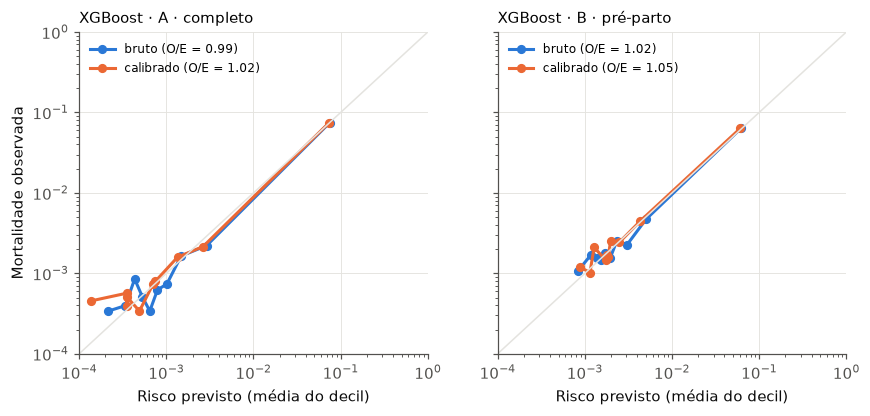

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, conj in zip(axes, preprocess.CONJUNTOS):
    cal = R["calibracao"][conj]
    for tipo, cor in [("bruto", COR["LR"]), ("calibrado", COR["XGBoost"])]:
        t = cal[tipo]
        ax.plot(t["previsto"], t["observado"], marker="o", ms=5, color=cor,
                label=f"{tipo} (O/E = {cal[f'OE_{tipo}']:.2f})")
    lim = [1e-4, 1]
    ax.plot(lim, lim, color=GRADE, lw=1)
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Risco previsto (média do decil)")
    ax.set_title(f"XGBoost · {NOME_CONJ[conj]}", loc="left", fontsize=10)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Mortalidade observada")
fig.savefig(FIG / "calibracao.png")

### 5.4 Interpretação (SHAP)
Os valores SHAP foram calculados com `TreeExplainer` numa amostra de 20.000 nascimentos de 2023. O
gráfico mostra a importância média |SHAP| das 12 principais variáveis. No artigo, as cinco primeiras
foram Apgar 5, peso, Apgar 1, anomalia congênita e idade gestacional.

,A · completo,B · pré-parto
0,Apgar 5º min,Semanas de gestação
1,Peso ao nascer,Consultas de pré-natal
2,Apgar 1º min,Escolaridade da mãe
3,Semanas de gestação,Apresentação
4,Anomalia congênita,Raça/cor da mãe


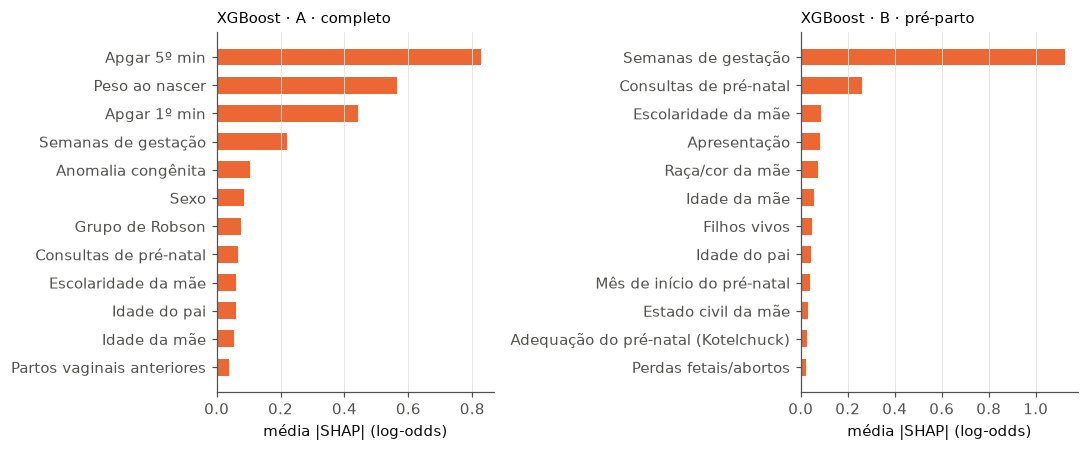

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
imp_todas = {}
for ax, conj in zip(axes, preprocess.CONJUNTOS):
    s = R["shap"][conj]
    imp = pd.Series(np.abs(s["valores"]).mean(0), index=s["X"].columns).rename(preprocess.ROTULOS)
    imp = imp.sort_values().tail(12)
    imp_todas[conj] = imp[::-1]
    ax.barh(imp.index, imp.values, color=COR["XGBoost"], height=0.6)
    ax.set_title(f"XGBoost · {NOME_CONJ[conj]}", loc="left", fontsize=10)
    ax.set_xlabel("média |SHAP| (log-odds)"); ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "shap_importancia.png")
pd.DataFrame({NOME_CONJ[c]: v.index[:5].tolist() for c, v in imp_todas.items()})

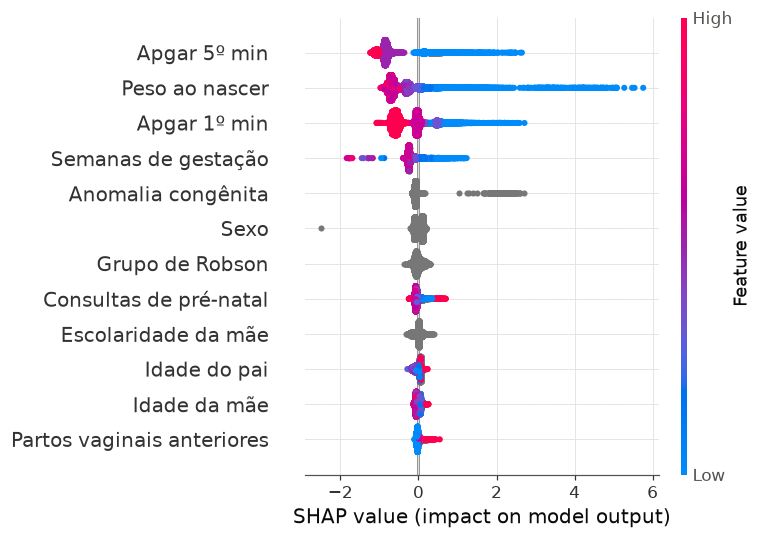

In [21]:
s = R["shap"]["A_completo"]
shap.summary_plot(s["valores"], s["X"].rename(columns=preprocess.ROTULOS), max_display=12, show=False,
                  plot_size=(7, 5))
plt.gcf().savefig(FIG / "shap_beeswarm_A.png")
plt.show()

### 5.5 Subgrupos: discriminação e calibração
Resultados do XGBoost recalibrado no teste de 2023, com IC 95% de 500 reamostras bootstrap dentro de cada
subgrupo. Subgrupos com menos de 20 óbitos (mães amarelas e indígenas) foram omitidos. Se os IC se
sobrepõem, a diferença entre os subgrupos não é distinguível do acaso.

In [22]:
teste = base[base["ano"] == preprocess.ANO_TESTE]
assert (teste["obito_neonatal"].to_numpy() == y_te).all()  # mesma ordem das predições gravadas
GRUPOS = {"raca_mae": "Raça/cor da mãe", "escol_mae": "Escolaridade da mãe", "capital": "Residência"}
ORDEM = {"raca_mae": ["Branca", "Parda", "Preta"],
         "escol_mae": ["Fund. incompleto ou menos", "Médio", "Superior"], "capital": ["Capital", "Interior"]}
sub = []
for conj in preprocess.CONJUNTOS:
    pr = R["predicoes"][(conj, "XGBoost")]
    d = teste[list(GRUPOS)].assign(y=y_te, p=pr["calibrado"], escore=pr["bruto"])
    d["capital"] = d["capital"].map({1.0: "Capital", 0.0: "Interior"})
    for g in GRUPOS:
        t = evaluate.por_subgrupo(d, g, col_escore="escore", n_bootstrap=500).rename(columns={g: "Subgrupo"})
        sub.append(t.assign(Conjunto=NOME_CONJ[conj], Variável=GRUPOS[g]))
sub = pd.concat(sub).set_index(["Conjunto", "Variável", "Subgrupo"])
sub.to_csv(FIG / "subgrupos.csv")
sub.round(3)

n  óbitos  TMN (‰)  AUROC  AUPRC    O/E  AUROC_inf  AUROC_sup  O/E_inf  O/E_sup
Conjunto      Variável            Subgrupo                                                                                                       
A · completo  Raça/cor da mãe     Branca                      57474     416    7.238  0.952  0.554  1.081      0.937      0.966    0.997    1.169
                                  Parda                       86599     726    8.383  0.956  0.596  1.012      0.945      0.966    0.956    1.074
                                  Preta                       29518     276    9.350  0.962  0.576  0.944      0.945      0.976    0.866    1.024
              Escolaridade da mãe Fund. incompleto ou menos   34904     353   10.113  0.950  0.533  1.023      0.935      0.965    0.945    1.111
                                  Médio                       98364     828    8.418  0.957  0.595  1.025      0.949      0.966    0.971    1.073
                                  Superior                    41321     247    5.978  0.953  0.579  0.988      0.932      0.969    0.889    1.075
              Residência          Capital                     62850     489    7.780  0.950  0.570  0.951      0.934      0.963    0.886    1.020
                                  Interior                   113295     955    8.429  0.959  0.580  1.052      0.952      0.967    1.000    1.103
B · pré-parto Raça/cor da mãe     Branca                      57474     416    7.238  0.882  0.372  1.148      0.860      0.902    1.053    1.244
                                  Parda                       86599     726    8.383  0.886  0.406  1.015      0.868      0.902    0.956    1.082
                                  Preta                       29518     276    9.350  0.918  0.469  0.999      0.895      0.938    0.906    1.092
              Escolaridade da mãe Fund. incompleto ou menos   34904     353   10.113  0.868  0.339  1.058      0.841      0.895    0.968    1.159
                                  Médio                       98364     828    8.418  0.891  0.428  1.048      0.876      0.905    0.989    1.106
                                  Superior                    41321     247    5.978  0.892  0.425  1.026      0.865      0.918    0.908    1.127
              Residência          Capital                     62850     489    7.780  0.882  0.423  0.981      0.859      0.903    0.900    1.059
                                  Interior                   113295     955    8.429  0.894  0.399  1.083      0.881      0.909    1.024    1.147

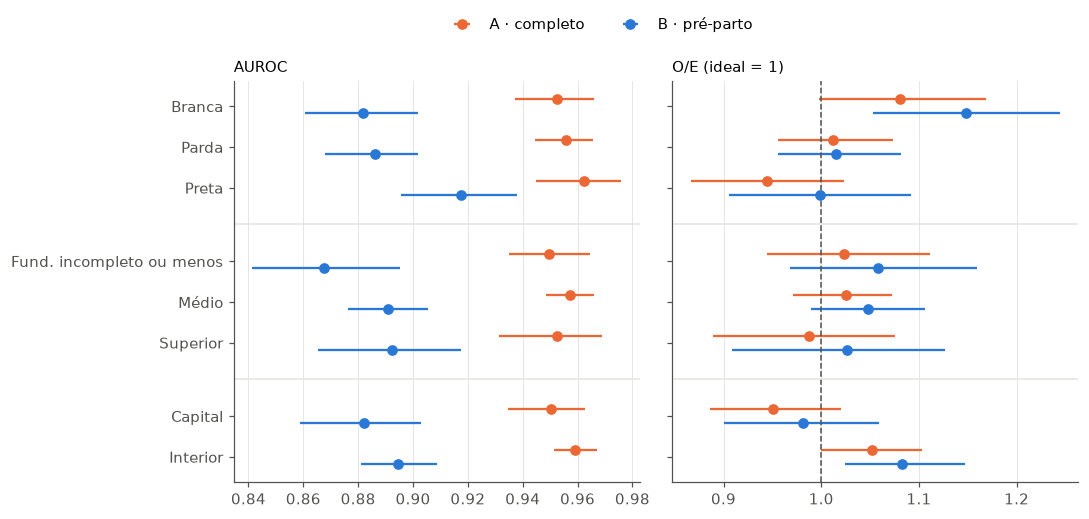

In [23]:
linhas = [(GRUPOS[g], nome) for g in GRUPOS for nome in ORDEM[g]]
ypos, y, rotulos, blocos = {}, 0, [], []
for i, (var, nome) in enumerate(linhas):
    if i and var != linhas[i - 1][0]:
        y += 0.8  # espaço entre blocos
        blocos.append(y - 0.9)
    ypos[(var, nome)] = y; rotulos.append(nome); y += 1
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
for ax, met, ref in [(axes[0], "AUROC", None), (axes[1], "O/E", 1.0)]:
    for conj, cor, desl in [("A · completo", COR["XGBoost"], -0.17), ("B · pré-parto", COR["LR"], 0.17)]:
        t = sub.loc[conj]
        yy = [ypos[k] + desl for k in t.index]
        ax.errorbar(t[met], yy, xerr=[t[met] - t[f"{met}_inf"], t[f"{met}_sup"] - t[met]], fmt="o", ms=6,
                    color=cor, ecolor=cor, elinewidth=1.5, capsize=0, label=conj)
    if ref:
        ax.axvline(ref, color=TINTA2, lw=1, ls="--")
    for yb in blocos:
        ax.axhline(yb, color=GRADE, lw=1)
    ax.set_title(met + (" (ideal = 1)" if ref else ""), loc="left", fontsize=10); ax.grid(axis="y", visible=False)
axes[0].set_yticks(list(ypos.values()), rotulos); axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.55, 1.03))
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG / "subgrupos.png")

### 5.6 Calibração fraca: intercepto e inclinação
Seguimos Van Calster et al. (2019).
- **Intercepto** (*calibration-in-the-large*): ideal 0; um valor positivo indica que o modelo subestima o risco.
- **Inclinação:** ideal 1; um valor menor que 1 indica previsões extremas demais.

A TMN subiu de 7,70‰ (2017–2022) para 8,20‰ no teste de 2023. Essa mudança de prevalência (*drift*) empurra
o O/E para cima de 1 mesmo num modelo bem calibrado no passado.

In [24]:
C = R["complementares"]
cal_tab = pd.DataFrame({(NOME_CONJ[c], t): v for c, d in C["calibracao"].items() for t, v in d.items()}).T
cal_tab.to_csv(FIG / "calibracao_intercepto_inclinacao.csv")
print("TMN por amostra (‰):", {k: round(v, 2) for k, v in C["tmn_por_amostra"].items()})
cal_tab.round(3)

TMN por amostra (‰): {'ajuste 2017–2021': np.float64(7.7), 'validação 2022': np.float64(7.7), 'teste 2023': np.float64(8.2)}


intercepto  intercepto_inf  intercepto_sup  inclinacao  inclinacao_inf  inclinacao_sup
A · completo  bruto          -0.020          -0.088           0.048       0.999           0.974           1.025
              calibrado       0.026          -0.041           0.094       0.984           0.958           1.010
B · pré-parto bruto           0.021          -0.040           0.081       1.013           0.988           1.038
              calibrado       0.063           0.002           0.124       0.993           0.968           1.018

### 5.7 Curva de calibração e utilidade clínica
- **Calibração** (painel da esquerda): mortalidade observada × prevista em 20 faixas de risco (quantis), em
  escala log, para a probabilidade bruta e a recalibrada. Intercepto e inclinação são calibração "fraca"; a
  curva é o nível recomendado por Van Calster et al.
- **Curva de decisão** (painel da direita): benefício líquido $NB(p_t) = \frac{VP}{n} - \frac{FP}{n}\cdot\frac{p_t}{1-p_t}$
  (Vickers e Elkin, 2006).
  - Com prevalência de 0,8%, "tratar todos" tem benefício negativo acima de $p_t$ ≈ 0,8%, então superá-la é
    trivial. A comparação relevante é com **tratar nenhum**.
  - A faixa sombreada, 2%–10%, corresponde a aceitar de 9 a 49 falsos alarmes por óbito identificado. É uma
    faixa plausível para decidir uma transferência *in utero*, que tem custo e risco, mas é muito menos grave
    do que um óbito evitável sem UTI.

modelo  tratar todos  tratar nenhum  fração sinalizada
              limiar                                                        
A · completo  0.02     0.006        -0.012            0.0              0.031
              0.05     0.006        -0.044            0.0              0.019
              0.10     0.005        -0.102            0.0              0.016
B · pré-parto 0.02     0.005        -0.012            0.0              0.036
              0.05     0.004        -0.044            0.0              0.017
              0.10     0.004        -0.102            0.0              0.012

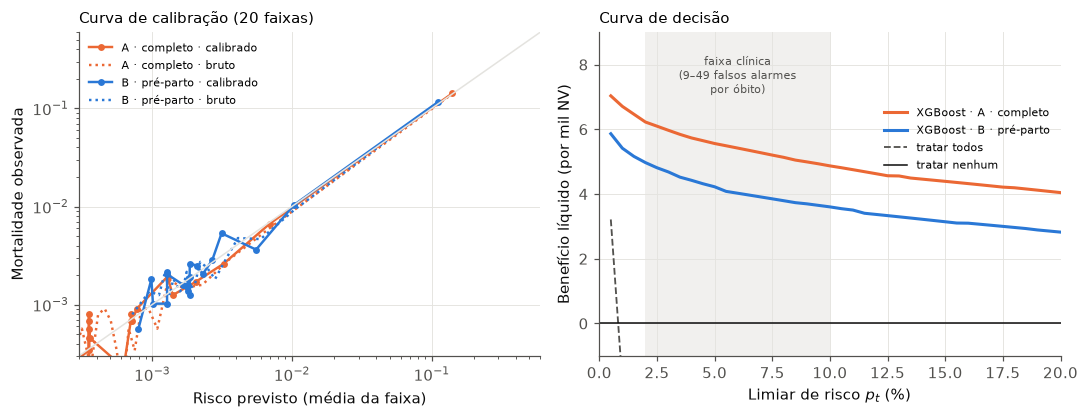

In [25]:
def curva_cal(y, p, n=20):
    d = pd.DataFrame({"y": y, "p": p})
    d["f"] = pd.qcut(d["p"].rank(method="first"), n, labels=False)
    return d.groupby("f").agg(previsto=("p", "mean"), observado=("y", "mean"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9))
for conj, cor in [("A_completo", COR["XGBoost"]), ("B_pre_parto", COR["LR"])]:
    for t, ls, mk in [("calibrado", "-", "o"), ("bruto", ":", "")]:
        c = curva_cal(y_te, R["predicoes"][(conj, "XGBoost")][t])
        ax1.plot(c["previsto"], c["observado"], ls=ls, marker=mk, ms=3.5, color=cor, lw=1.6,
                 label=f"{NOME_CONJ[conj]} · {t}")
lim = [3e-4, 0.6]
ax1.plot(lim, lim, color=GRADE, lw=1)
ax1.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Risco previsto (média da faixa)",
        ylabel="Mortalidade observada")
ax1.set_title("Curva de calibração (20 faixas)", loc="left", fontsize=10); ax1.legend(fontsize=7.5)
ax2.axvspan(2, 10, color=GRADE, alpha=0.5, lw=0)
for conj, cor in [("A_completo", COR["XGBoost"]), ("B_pre_parto", COR["LR"])]:
    d = C["decisao"][conj]; d = d[d["limiar"] <= 0.2]
    ax2.plot(d["limiar"] * 100, d["modelo"] * 1000, color=cor, label=f"XGBoost · {NOME_CONJ[conj]}")
d = C["decisao"]["A_completo"]; d = d[d["limiar"] <= 0.2]
ax2.plot(d["limiar"] * 100, d["tratar todos"] * 1000, color=TINTA2, ls="--", lw=1.2, label="tratar todos")
ax2.axhline(0, color=TINTA, lw=1, label="tratar nenhum")
ax2.set(xlabel="Limiar de risco $p_t$ (%)", ylabel="Benefício líquido (por mil NV)", ylim=(-1, 9), xlim=(0, 20))
ax2.text(6, 8.3, "faixa clínica\n(9–49 falsos alarmes\npor óbito)", ha="center", fontsize=7.5, color=TINTA2, va="top")
ax2.set_title("Curva de decisão", loc="left", fontsize=10); ax2.legend(fontsize=7.5, loc="upper right", bbox_to_anchor=(1, 0.8))
fig.tight_layout()
fig.savefig(FIG / "calibracao_decisao.png")
pd.concat({NOME_CONJ[c]: d.set_index("limiar").loc[[0.02, 0.05, 0.1]] for c, d in C["decisao"].items()}).round(5)

### 5.8 Viés do linkage: óbitos pareados × não pareados
Os óbitos não pareados continuam na base rotulados como sobreviventes. Para ver quem eles são, comparamos as
características que a própria Declaração de Óbito informa, sem depender do pareamento. As chaves exigem peso,
idade da mãe e semanas preenchidos, então um óbito com esses campos ausentes tem menos chance de ser pareado.

In [26]:
vl = C["vies_linkage"]
vl["perfil"].to_csv(FIG / "vies_linkage_perfil.csv")
vl["por_subgrupo"].to_csv(FIG / "vies_linkage_subgrupos.csv", index=False)
vl["perfil"].round(1)

,Pareados,Não pareados
n,10849.0,1190.0
Peso ausente (%),0.8,26.7
Peso < 1.500 g (%),60.1,51.9
Peso mediano (g),1100.0,1407.5
Semanas ausentes (%),4.9,31.6
Semanas < 32 (%),58.9,51.5
Idade da mãe ausente (%),2.1,32.5
Óbito no 1º dia (%),26.3,31.8
Óbito com 7–27 dias (%),27.8,32.9
Residente na capital (%),35.2,19.6


In [27]:
vl["por_subgrupo"].round(1)

,Variável,Categoria,Óbitos,Pareados (%)
0,Residência,Capital,4055,94.3
1,Residência,Interior,7984,88.0
2,Raça/cor do recém-nascido (DO),Branca,3970,89.1
3,Raça/cor do recém-nascido (DO),Outra/ignorada,804,91.3
4,Raça/cor do recém-nascido (DO),Parda,6550,90.5
5,Raça/cor do recém-nascido (DO),Preta,715,90.5
6,Peso na DO,ausente,403,21.1
7,Peso na DO,preenchido,11636,92.5


### 5.9 Sensibilidade ao linkage
O XGBoost foi refeito com os mesmos hiperparâmetros e rótulos alternativos **no treino e na validação**.
- **Estrito:** os nascimentos pareados nas passadas 3–6 saem.
- **Pior caso:** esses nascimentos ficam, mas rotulados como sobreviventes.

A avaliação é no **mesmo teste de 2023 completo**, com os rótulos principais. Assim, a diferença de AUROC em
relação ao modelo principal pode ser testada por bootstrap pareado.

In [28]:
linhas = []
for (conj, cen), v in C["sensibilidade"].items():
    m, d = v["metricas"]["valor"], v["delta_auroc"]
    linhas.append({"Conjunto": NOME_CONJ[conj], "Cenário": cen, "Óbitos no treino": v["positivos_treino"],
                   "AUROC": m["AUROC"], "AUPRC": m["AUPRC"], "Top 5%": m["Óbitos no top 5%"], "O/E": m["O/E"],
                   "ΔAUROC vs principal": d["delta"], "IC inf": d["ic_inf"], "IC sup": d["ic_sup"]})
for conj in preprocess.CONJUNTOS:
    m = R["metricas"][(conj, "XGBoost")]["valor"]
    linhas.append({"Conjunto": NOME_CONJ[conj], "Cenário": "principal", "AUROC": m["AUROC"], "AUPRC": m["AUPRC"],
                   "Top 5%": m["Óbitos no top 5%"], "O/E": m["O/E"]})
sens = pd.DataFrame(linhas).sort_values(["Conjunto", "Cenário"]).set_index(["Conjunto", "Cenário"])
sens.to_csv(FIG / "sensibilidade_linkage.csv")
sens.round(4)

Óbitos no treino  AUROC  AUPRC  Top 5%    O/E  ΔAUROC vs principal     IC inf     IC sup
Conjunto      Cenário                                                                                            
A · completo  estrito              6516.0  0.956  0.575   0.868  1.152           -1.000e-04 -8.000e-04  6.000e-04
              pior caso            6516.0  0.956  0.569   0.870  1.228           -5.000e-04 -1.400e-03  4.000e-04
              principal               NaN  0.956  0.576   0.868  1.016                  NaN        NaN        NaN
B · pré-parto estrito              6516.0  0.891  0.407   0.713  1.210            1.100e-03 -1.000e-04  2.500e-03
              pior caso            6516.0  0.890  0.407   0.716  1.266            2.000e-04 -1.300e-03  1.400e-03
              principal               NaN  0.890  0.406   0.716  1.046                  NaN        NaN        NaN

### 5.10 Explicabilidade (XAI)
O SHAP (`TreeExplainer`) decompõe o log-odds previsto de cada nascimento em contribuições aditivas das
variáveis: $\text{logit}\,\hat p = \phi_0 + \sum_j \phi_j$. A análise tem quatro partes:
1. **Global:** importância média |SHAP| (seção 5.4).
2. **Dependência:** SHAP em função do valor da variável. O efeito aprendido faz sentido clinicamente?
3. **Local:** explicação de casos individuais, isto é, por que o modelo acertou ou errou.
4. **Estabilidade e atributos sensíveis:** o ranking muda entre algoritmos ou amostras? Quanto raça/cor e
   escolaridade pesam nas explicações?

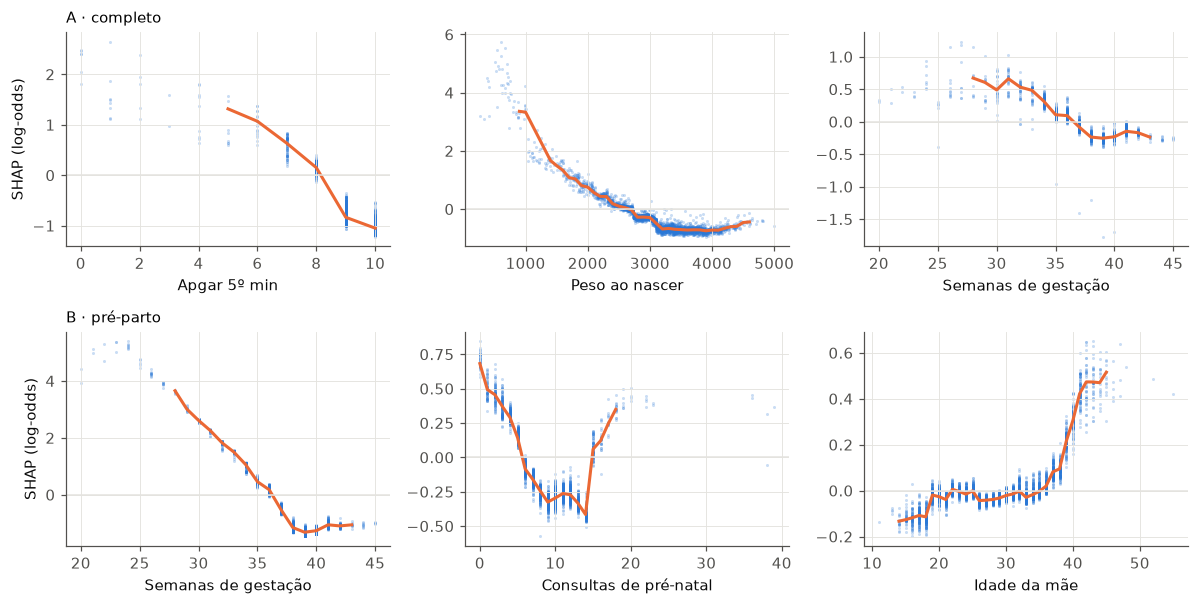

In [29]:
X_ = C["xai"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for i, conj in enumerate(preprocess.CONJUNTOS):
    for j, (v, d) in enumerate(X_["dependencia"][conj].items()):
        ax = axes[i, j]
        d = d.dropna()
        amostra = d.sample(min(6000, len(d)), random_state=0)
        ax.scatter(amostra["x"], amostra["shap"], s=4, alpha=0.25, color=COR["LR"], linewidths=0)
        m = d.groupby(d["x"].round(0 if v != "PESO" else -2))["shap"].median()
        m = m[d.groupby(d["x"].round(0 if v != "PESO" else -2)).size() >= 30]
        ax.plot(m.index, m.values, color=COR["XGBoost"], lw=2)
        ax.axhline(0, color=GRADE, lw=1)
        ax.set_xlabel(preprocess.ROTULOS[v]); ax.set_ylabel("SHAP (log-odds)" if j == 0 else "")
        ax.set_title(NOME_CONJ[conj] if j == 0 else "", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "xai_dependencia.png")

**Explicações locais.** São três casos do teste de 2023, no modelo completo: o óbito de maior risco previsto,
um óbito que o modelo não sinalizou (falso negativo mediano) e o sobrevivente de maior risco previsto (falso
positivo). O ponto de partida é o risco médio ($\phi_0$), e cada barra soma ou subtrai log-odds.

Risco de base φ0: 0.53% | erro de aditividade máx.: 2.6077032e-08


valor   shap
                    variavel                          
Verdadeiro positivo Peso ao nascer        374.0  4.170
                    Apgar 5º min            0.0  1.495
                    Apgar 1º min            1.0  1.460
                    Semanas de gestação    20.0  0.426
                    Anomalia congênita        9  0.299
                    Idade do pai           33.0  0.115
Falso negativo      Apgar 1º min            5.0  1.115
                    Apgar 5º min            7.0  0.519
                    Peso ao nascer       2232.0  0.408
                    Semanas de gestação    34.0  0.207
                    Anomalia congênita        2 -0.129
                    Sexo                      1  0.114
Falso positivo      Apgar 1º min            1.0  2.637
                    Apgar 5º min            1.0  1.880
                    Anomalia congênita        1  1.820
                    Peso ao nascer       1940.0  1.123
                    Grupo de Robson           5  0.181
                    Idade do pai           54.0  0.174

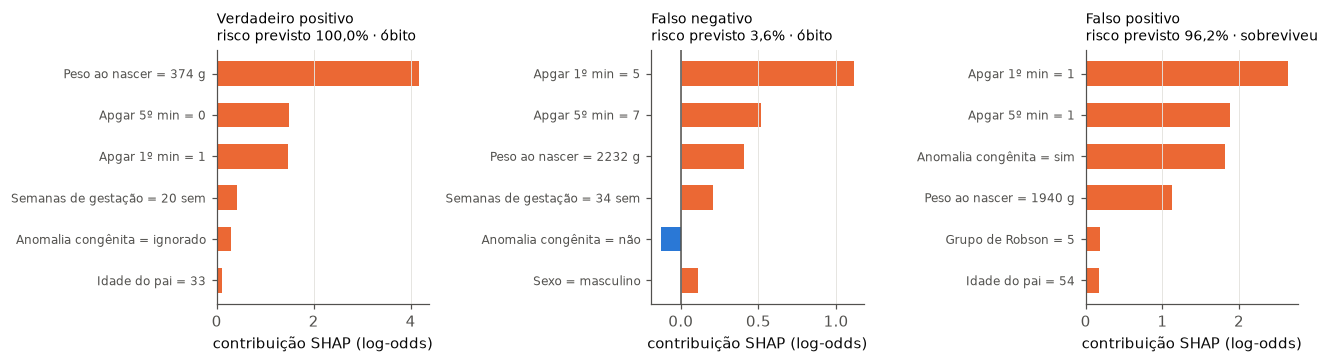

In [30]:
CODIGOS = {"Anomalia congênita": {"1": "sim", "2": "não", "9": "ignorado"},
           "Sexo": {"1": "masculino", "2": "feminino"}, "Tipo de gravidez": {"1": "única", "2": "dupla"},
           "Tipo de parto": {"1": "vaginal", "2": "cesáreo"}}


def legivel(var, valor):
    if var in CODIGOS:
        return CODIGOS[var].get(str(valor), str(valor))
    try:
        v = float(valor)
    except ValueError:
        return str(valor)
    txt = f"{v:.0f}"
    return txt + " g" if var == "Peso ao nascer" else (txt + " sem" if var == "Semanas de gestação" else txt)


loc = X_["locais"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (nome, c) in zip(axes, loc["casos"].items()):
    t = c["top"].iloc[::-1]
    rot = [f"{r.variavel} = {legivel(r.variavel, r.valor)}" for r in t.itertuples()]
    ax.barh(rot, t["shap"], color=[COR["XGBoost"] if v > 0 else COR["LR"] for v in t["shap"]], height=0.6)
    ax.axvline(0, color=TINTA2, lw=1)
    desfecho = "óbito" if c["obito"] else "sobreviveu"
    ax.set_title(f"{nome}\nrisco previsto {100 * c['prob_calibrada']:.1f}% · {desfecho}".replace(".", ","),
                 loc="left", fontsize=9)
    ax.set_xlabel("contribuição SHAP (log-odds)"); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "xai_local.png")
print(f"Risco de base φ0: {100 * loc['base_prob']:.2f}% | erro de aditividade máx.:",
      max(c["aditividade_erro"] for c in loc["casos"].values()))
pd.concat({k: v["top"].set_index("variavel") for k, v in loc["casos"].items()}).round(3)

**Estabilidade e atributos sensíveis.**

In [31]:
est = pd.DataFrame({NOME_CONJ[c]: {k: v for k, v in e.items() if k != "importancia_lgbm"}
                    for c, e in X_["estabilidade"].items()}).T
sens_attr = pd.DataFrame({NOME_CONJ[c]: {preprocess.ROTULOS[k]: v for k, v in s_["fracao_importancia"].items()}
                          for c, s_ in X_["sensiveis"].items()}).T
est.to_csv(FIG / "xai_estabilidade.csv"); sens_attr.to_csv(FIG / "xai_sensiveis.csv")
display(est.round(3)); display((100 * sens_attr).round(1))
X_["sensiveis"]["B_pre_parto"]["RACACORMAE"].rename(index={"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda",
                                                            "5": "Indígena", "ausente": "Ignorada"}).round(3)

,spearman_xgb_lgbm,top5_comum_xgb_lgbm,spearman_metades,top5_comum_metades
A · completo,0.959,4.0,0.999,5.0
B · pré-parto,0.892,4.0,1.000,5.0


,Raça/cor da mãe,Escolaridade da mãe
A · completo,1.2,2.1
B · pré-parto,3.8,4.3


,mean,size
categoria,,
Branca,-0.129,6493
Preta,0.084,3375
Amarela,0.143,118
Parda,0.030,9826
Indígena,0.147,25
Ignorada,0.239,163


### 5.11 Avaliação das premissas
- **Colinearidade (regressão logística):** as contagens do histórico obstétrico são quase uma soma umas das
  outras (gestações ≈ partos + perdas). O VIF mede quanto isso infla a variância dos coeficientes. A
  colinearidade afeta a interpretação dos coeficientes, mas não a predição. A penalização L2 estabiliza o ajuste,
  e as árvores não dependem dessa premissa.
- **Mecanismo dos ausentes:** se a TMN difere muito entre registros com e sem o campo, a ausência não é
  aleatória (MCAR descartado). Ela é informativa, e por isso usamos indicadores de ausência ou a categoria
  "ignorado", em vez de só imputar.
- **Independência:** gêmeos compartilham mãe e gestação. Medimos quanto eles pesam e se a AUROC muda sem eles.

In [32]:
C["colinearidade"].round(2)

,VIF
Filhos vivos,18.18
Gestações anteriores,17.08
Partos vaginais anteriores,6.54
Perdas fetais/abortos,3.68
Cesáreas anteriores,2.90
Apgar 5º min,1.98
Apgar 1º min,1.97
Semanas de gestação,1.60
Idade da mãe,1.54
Peso ao nascer,1.53


In [33]:
C["ausencia"].round(2)

,Variável,Ausente (%),TMN ausente (‰),TMN preenchido (‰)
0,Idade do pai,54.15,8.77,6.58
1,Consultas de pré-natal,2.36,18.92,7.50
2,Mês de início do pré-natal,6.65,16.96,7.11
3,Semanas de gestação,1.19,13.40,7.70
4,Apgar 5º min,1.08,27.18,7.55
5,Peso ao nascer,0.00,0.00,7.76
6,Anomalia congênita (ignorado),2.86,8.10,7.75
7,Escolaridade da mãe (ignorado),1.71,8.98,7.74
8,Raça/cor da mãe (ignorado),1.80,8.45,7.75


In [34]:
pd.Series(C["gemelares"]).round(4)

% múltiplos                      2.402
% dos óbitos em múltiplos        8.934
AUROC A_completo (todos)         0.956
AUROC A_completo (só únicos)     0.954
AUROC B_pre_parto (todos)        0.890
AUROC B_pre_parto (só únicos)    0.884
dtype: float64

## 6. Conclusão
O resumo dos resultados, a discussão e as limitações estão no `README.md` e em `relatorio/main.pdf`.
Todos os números citados nesses documentos saem das tabelas acima.

A execução completa levou:

In [35]:
print(f"{R['tempo_total_s'] / 60:.0f} min")

36 min
